# Machine Learning Fundamentals
## Unit 08 — Cross-Validation

**Stage 2: Machine Learning | Beginner level | English B2**  
**Business scenario:** Melbourne house-price estimation  
**Environment:** Google Colab / Jupyter Notebook  
**Libraries:** Pandas, Matplotlib, scikit-learn

---

## Business question

A model's score can change depending on which rows appear in a single validation set. How can we evaluate a model across several data splits to get a more stable estimate of its performance?

In this lesson, we use **five-fold cross-validation** to evaluate a Random Forest pipeline for predicting house prices. We inspect each fold's MAE, summarize the results, and discuss what the scores can and cannot tell us.

### Learning outcomes

By the end of this notebook, you should be able to:

- Explain why a single validation score may depend on the chosen split.
- Describe the steps in k-fold cross-validation.
- Explain the role of training folds and the held-out fold.
- Use `cross_val_score()` with a scikit-learn pipeline.
- Explain why `neg_mean_absolute_error` returns negative values.
- Interpret mean MAE and standard deviation across folds.
- Explain why preprocessing must be fitted inside each training fold.

### Lesson map

1. Why validation scores can vary
2. How five-fold cross-validation works
3. Prepare the Melbourne data
4. Build a leakage-aware pipeline
5. Run cross-validation
6. Interpret and visualize the results
7. Practical challenge and readiness checklist

**Dataset:** `melb_data.csv`, containing historical Melbourne property records. These examples are for learning and are not current property valuations.

---
# 1. Introduction

Machine learning is an iterative process. You will make choices about which features to use, which model to train, and which model settings to choose.

So far, we have measured model quality using a validation set, also called a holdout set. This is useful, but the result can depend on which rows happen to be in that set.

Imagine a dataset with 5,000 rows. If you reserve 20% for validation, your score is based on 1,000 rows. A model might perform well on those particular rows but perform differently on another set of 1,000 rows.

A validation score is an estimate of how well a model may perform on new data. Cross-validation helps us make this estimate more reliable by repeating the training and validation process on different subsets of the data.


---
# 2. What Is Cross-Validation?

In **k-fold cross-validation**, we divide the data into *k* parts, called **folds**. We then run one experiment for each fold:

1. Select one fold as the validation set.
2. Use all the other folds as training data.
3. Train the model on the training folds.
4. Evaluate it on the validation fold.
5. Repeat until every fold has been used for validation once.

For five-fold cross-validation, each experiment uses about 80% of the rows for training and 20% for validation. Every row is included in a validation fold once.


<div align="center">
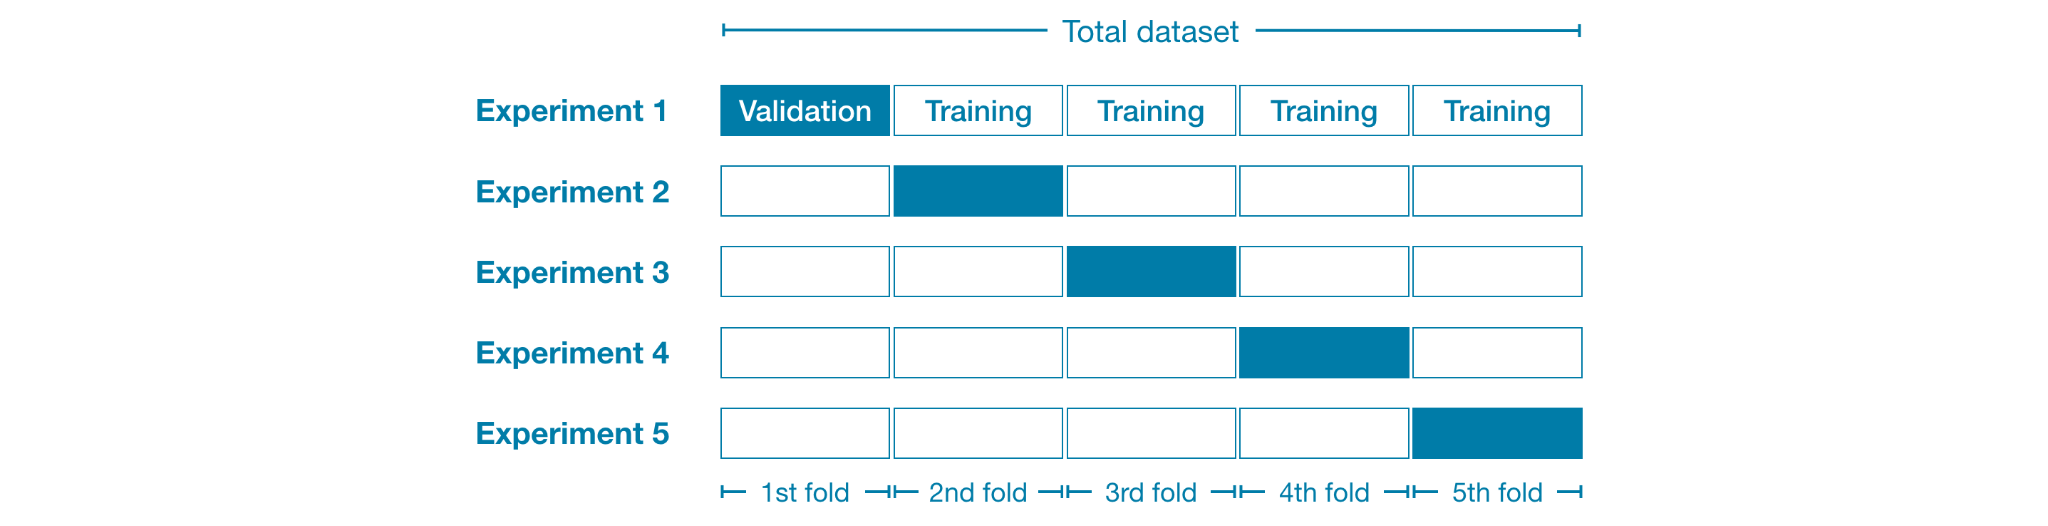
</div>

## 2.1 Read the Diagram

The diagram shows five experiments:

- **Experiment 1:** Fold 1 is used for validation; folds 2–5 are used for training.
- **Experiment 2:** Fold 2 is used for validation; the other folds are used for training.
- **Experiment 3:** Fold 3 is used for validation.
- **Experiment 4:** Fold 4 is used for validation.
- **Experiment 5:** Fold 5 is used for validation.

Each experiment produces a separate model-quality score. We usually calculate the average of these scores to compare models.

**Important:** Cross-validation is normally used on the training data during model development. Keep a separate test set for a final, unbiased evaluation when the project requires one.


## 2.2 Why Not Use Only One Validation Set?

A single validation split is usually faster because it requires training one model. Cross-validation trains and evaluates multiple models, so it takes more time.

| Approach | Advantage | Limitation |
|---|---|---|
| One validation split | Faster and simple | The score may depend on the chosen split |
| Cross-validation | Provides scores across multiple splits | Requires more model training |

Cross-validation is often useful for small or medium-sized datasets, especially when model training is reasonably fast. For very large datasets or expensive models, one holdout set may be a practical choice.


---
# 3. Prepare the Data

We'll use the Melbourne Housing dataset and a small set of numerical features. The target variable is `Price`.

The selected features are:

- `Rooms`
- `Distance`
- `Landsize`
- `BuildingArea`
- `YearBuilt`

Some features contain missing values. We will use a pipeline to impute those values during each cross-validation experiment.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the data
melbourne_file_path = 'melb_data.csv'
data = pd.read_csv(melbourne_file_path)

# Select a subset of predictors
cols_to_use = [
    'Rooms',
    'Distance',
    'Landsize',
    'BuildingArea',
    'YearBuilt'
]
X = data[cols_to_use]

# Select the target
y = data.Price

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFirst five rows:")
display(X.head())

## 3.1 Inspect Missing Values

Before modeling, check whether the selected features contain missing values. The pipeline will handle these values, but inspecting them first helps us understand the data.

A missing value is not the same as zero. For example, a missing `BuildingArea` means the area was not recorded; zero would mean the recorded area is actually zero.

In [ ]:
missing_counts = X.isnull().sum()
print("Missing values by feature:")
print(missing_counts[missing_counts > 0])

---
# 4. Build a Pipeline

A **pipeline** connects preprocessing and modeling into one reusable workflow.

Our pipeline has two steps:

1. **Preprocessor:** `SimpleImputer()` replaces missing numeric values with the mean of that feature.
2. **Model:** `RandomForestRegressor` learns patterns from the prepared data and predicts house prices.

### Why is this important for cross-validation?

During each fold, the imputer learns the mean from that fold's training portion only. It then uses those learned values to transform the held-out fold. Because the imputer is inside the pipeline, this process is repeated correctly for every fold.

If we calculated imputation values using the entire dataset before cross-validation, information from held-out folds could influence preprocessing. This is a form of **data leakage**.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

my_pipeline = Pipeline(steps=[
    ('preprocessor', SimpleImputer()),
    ('model', RandomForestRegressor(
        n_estimators=50,
        random_state=0,
        n_jobs=-1
    ))
])

my_pipeline

---
# 5. Run Cross-Validation

We use `cross_val_score()` from scikit-learn. Setting `cv=5` requests five-fold cross-validation.

For each fold:
1. Four folds are used to fit the pipeline.
2. The remaining fold is used to evaluate predictions.
3. The process repeats until every fold has served as the validation fold once.

We use `scoring='neg_mean_absolute_error'`. Scikit-learn follows a convention where larger scores are better, so error metrics are returned as negative values. We multiply by `-1` to make them ordinary positive MAE values.

We define an explicit shuffled `KFold` splitter with a fixed `random_state` for reproducibility.

In [ ]:
from sklearn.model_selection import cross_val_score, KFold

cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

negative_mae_scores = cross_val_score(
    my_pipeline,
    X,
    y,
    cv=cv_strategy,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative MAE scores into positive error values.
scores = -negative_mae_scores

print("Validation MAE for each fold:")
for fold_number, score in enumerate(scores, start=1):
    print(f"Fold {fold_number}: AUD {score:,.2f}")

## 5.1 Why Is the Score Negative?

Scikit-learn's model-selection tools follow a convention where **higher scores are better**. For loss metrics such as Mean Absolute Error, lower errors are better, so scikit-learn exposes the scorer as `neg_mean_absolute_error`.

This means the raw values returned by `cross_val_score()` are negative. We multiply them by `-1` to recover ordinary positive MAE values.

After conversion:

- A lower MAE means smaller average absolute prediction errors.
- Compare models using the same folds and the same metric.
- Do not compare MAE values from different target units as if they were equivalent.

---
# 6. Interpret the Results

We usually want one summary value when comparing candidate models. A simple approach is to calculate the average MAE across the folds.

We can also calculate the standard deviation to understand how much the scores vary from one fold to another. A high variation may indicate that performance depends strongly on which rows are used for validation.


In [ ]:
mean_mae = scores.mean()
std_mae = scores.std(ddof=0)
min_mae = scores.min()
max_mae = scores.max()

print(f"Mean MAE across folds:       AUD {mean_mae:,.2f}")
print(f"Standard deviation (folds):  AUD {std_mae:,.2f}")
print(f"Lowest fold MAE:              AUD {min_mae:,.2f}")
print(f"Highest fold MAE:             AUD {max_mae:,.2f}")
print(f"Range between folds:          AUD {max_mae - min_mae:,.2f}")

In [ ]:
fold_results = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, len(scores) + 1)],
    "Validation MAE (AUD)": scores
})
display(fold_results.style.format({"Validation MAE (AUD)": "AUD {:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(fold_results["Fold"], fold_results["Validation MAE (AUD)"])
ax.axhline(mean_mae, linestyle="--", label=f"Mean MAE = AUD {mean_mae:,.0f}")
ax.set_title("Five-Fold Cross-Validation: MAE by Fold")
ax.set_ylabel("Validation MAE (AUD)")
ax.set_xlabel("Validation fold")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:** A higher fold MAE means the model made larger average absolute errors on that fold. The mean summarizes performance across folds, while the standard deviation describes how much the fold scores vary. The standard deviation is not a confidence interval.

## 6.1 Reference Results vs. Your Run

The original Kaggle lesson reports five-fold MAE values of approximately:

- AUD 301,629
- AUD 303,164
- AUD 287,298
- AUD 236,062
- AUD 260,383

Its reported average is approximately **AUD 277,707**.

Your results may differ because of dataset versions, selected features, model settings, split strategy, and library versions. Use the values generated by this notebook as evidence for your own discussion; treat the reference figures as historical examples, not required outputs.

## 6.1 What Do the Scores Tell Us?

- The **average MAE** gives a summary of the model's validation error across all folds.
- The **standard deviation** describes how much the fold scores vary around their average.
- The individual fold scores help us see whether the model performs similarly across different subsets.

Cross-validation does not guarantee that a model will perform equally well on every future dataset. It provides a more informed estimate than relying on a single validation split alone.


## 6.2 What Cross-Validation Does — and Does Not — Tell Us

Cross-validation gives several estimates across different splits, but it does not guarantee that future performance will be identical.

**Keep a final test set separate when you need a final performance estimate.** If you repeatedly use cross-validation results to choose features or model settings, those results become part of the model-selection process. A separate test set can provide a final check after those choices are complete.

## 6.2 Practical Note: Cross-Validation and Data Leakage

Preprocessing steps should be learned from each training fold, not from the entire dataset before cross-validation. Putting the imputer and model inside a pipeline ensures that each fold's preprocessing is fitted using only that fold's training rows.

This is one reason pipelines and cross-validation work well together. For more details, see the scikit-learn guidance on [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) and [common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html).


---
# 7. Conclusion and Practice

Cross-validation gives us several measures of model quality instead of relying on a single train-validation split.

In this lesson, you learned to:

- Explain the purpose of cross-validation.
- Describe five-fold cross-validation using the fold diagram.
- Build a pipeline containing imputation and a Random Forest model.
- Calculate fold scores with `cross_val_score()`.
- Convert negative MAE scores into positive error values.
- Summarize performance using the mean and standard deviation.

## Your Turn

Put your new skills to work in the next Kaggle exercise.

**[Open Kaggle — Intermediate Machine Learning: Cross-Validation](https://www.kaggle.com/learn/intermediate-machine-learning/lesson/5)**

[Open the full Intermediate Machine Learning course](https://www.kaggle.com/learn/intermediate-machine-learning)

### Practical challenge

1. Run five-fold cross-validation and record the average MAE.
2. Change `n_estimators` from `50` to `100` and compare the average MAE.
3. Compare the standard deviation for both experiments.
4. Explain why we use a pipeline for preprocessing during cross-validation.
5. Explain why a lower MAE indicates better predictive performance.

### Practice checklist

- [ ] I can explain what a fold is.
- [ ] I can describe the five experiments in five-fold cross-validation.
- [ ] I can use `cross_val_score()`.
- [ ] I can explain the negative MAE scoring convention.
- [ ] I can calculate and interpret average MAE.
- [ ] I can explain why preprocessing belongs inside the pipeline.

## Key takeaway

**Cross-validation evaluates a model across multiple data splits, giving a more reliable picture of its performance than a single split alone.**


---
## References

- [Kaggle — Intermediate Machine Learning: Cross-Validation](https://www.kaggle.com/learn/intermediate-machine-learning/lesson/5)
- [scikit-learn — Cross-validation guide](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn — `cross_val_score()` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
- [scikit-learn — Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
